## **Exploratory Data Analysis (EDA)**

**Tujuan**

Melakukan eksplorasi data untuk mengidentifikasi pola aktivitas pembelajaran, membandingkan keterlibatan mahasiswa berdasarkan hasil pembelajaran, serta menghasilkan visualisasi yang mendukung analisis dan rekomendasi berbasis data.

**Pertanyaan Bisnis**

1. Bagaimana distribusi hasil akhir pembelajaran?
2. Bagaimana distribusi tingkat aktivitas mahasiswa?
3. Bagaimana perbedaan engagement berdasarkan hasil akhir pembelajaran?
4. Apakah mahasiswa dengan engagement lebih tinggi cenderung memiliki hasil pembelajaran lebih baik?

####  **Mengimpor Library dan Menghubungkan Google Drive**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

base_path = Path("/content/drive/MyDrive/Data_Analytics/edtech-learning-analytics")

processed_path = base_path / "data" / "processed"
images_path = base_path / "images"

images_path.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### **Memuat Dataset yang Telah Diproses**

In [ ]:
student_info = pd.read_csv(processed_path / "studentInfo_clean.csv")

student_engagement = pd.read_csv(processed_path / "student_engagement.csv")

print("Student Info:", student_info.shape)
print("Student Engagement:", student_engagement.shape)

Student Info: (32593, 12)
Student Engagement: (29228, 6)


#### **Menggabungkan Dataset**

In [ ]:
student_key = ["code_module", "code_presentation", "id_student"]

eda_data = student_info.merge(
    student_engagement,
    on=student_key,
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Ukuran dataset gabungan:", eda_data.shape)

print("\nHasil merge:")
print(eda_data["_merge"].value_counts())

Ukuran dataset gabungan: (32593, 16)

Hasil merge:
_merge
both          29228
left_only      3365
right_only        0
Name: count, dtype: int64


In [ ]:
# Menangani Nilai Keterlibatan yang Hilang
eda_data["has_vle_activity"] = (eda_data["_merge"] == "both")

engagement_columns = ["total_clicks", "active_days", "unique_resources"]

eda_data[engagement_columns] = (eda_data[engagement_columns].fillna(0))

eda_data = eda_data.drop(columns="_merge")

print(eda_data[engagement_columns].isna().sum())

total_clicks        0
active_days         0
unique_resources    0
dtype: int64


#### **Distribusi Hasil Pembelajaran**

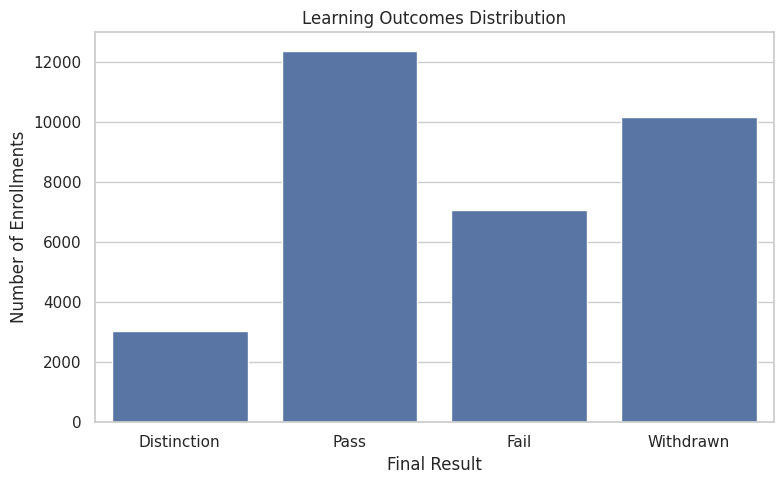

In [ ]:
result_order = ["Distinction", "Pass", "Fail", "Withdrawn"]

plt.figure(figsize=(8, 5))

sns.countplot(data=eda_data, x="final_result", order=result_order)

plt.title("Learning Outcomes Distribution")
plt.xlabel("Final Result")
plt.ylabel("Number of Enrollments")

plt.tight_layout()

plt.savefig(images_path / "learning_outcomes_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

### **Distribusi Keterlibatan mahasiswa**

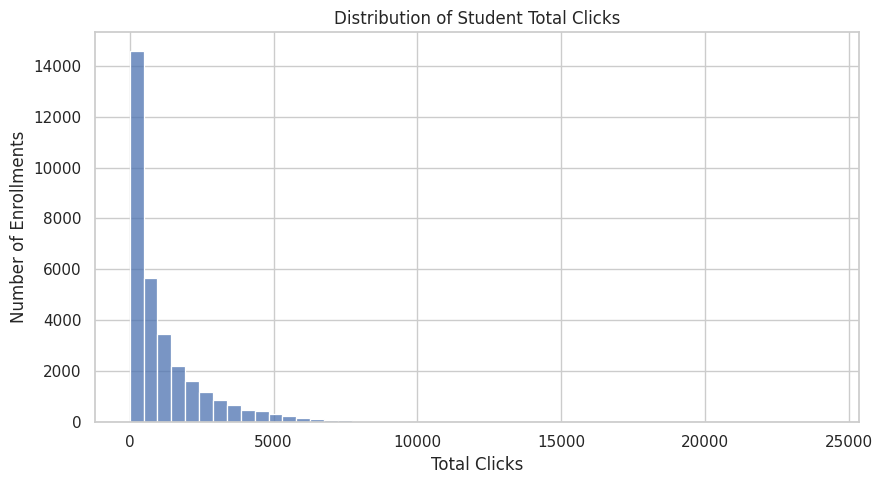

In [ ]:
# Distribusi Total Klik Asli
plt.figure(figsize=(9, 5))

sns.histplot(data=eda_data, x="total_clicks", bins=50)

plt.title("Distribution of Student Total Clicks")
plt.xlabel("Total Clicks")
plt.ylabel("Number of Enrollments")

plt.tight_layout()

plt.savefig(images_path / "student_engagement_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

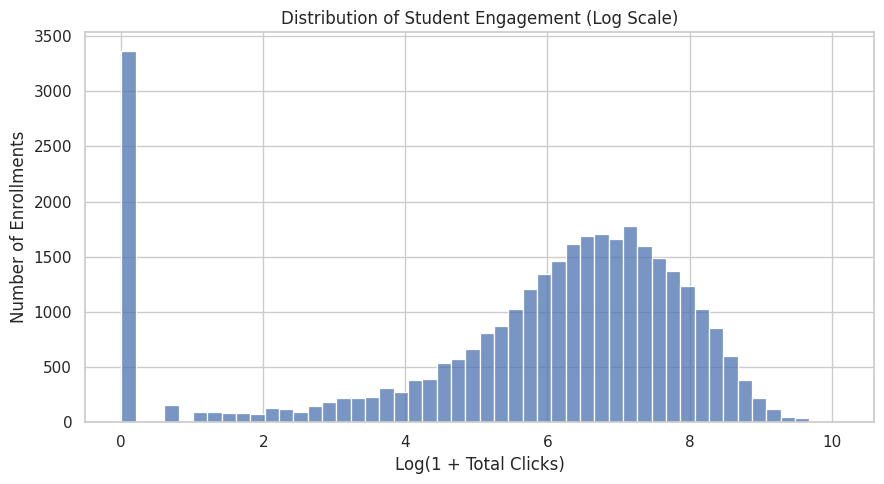

In [ ]:
# Distribusi Total Klik yang Ditransformasi Log
plt.figure(figsize=(9, 5))

sns.histplot(
    x=eda_data["total_clicks"].apply(
        lambda x: __import__("numpy").log1p(x)
    ),
    bins=50
)

plt.title("Distribution of Student Engagement (Log Scale)")
plt.xlabel("Log(1 + Total Clicks)")
plt.ylabel("Number of Enrollments")

plt.tight_layout()

plt.savefig(images_path / "student_engagement_log_distribution.png", dpi=300, bbox_inches="tight")

plt.show()


#### **Analisis Keterlibatan Berdasarkan Hasil Akademik**

In [ ]:
# Perbandingan rata-rata total klik pada setiap kategori hasil akhir pembelajaran
engagement_summary = (
    eda_data
    .groupby("final_result")[
        ["total_clicks", "active_days", "unique_resources"]
    ]
    .mean()
    .round(2)
)

print(engagement_summary)

              total_clicks  active_days  unique_resources
final_result                                             
Distinction        2666.76       110.04            102.45
Fail                651.85        33.18             43.08
Pass               1921.81        87.04             89.06
Withdrawn           313.95        16.29             24.23


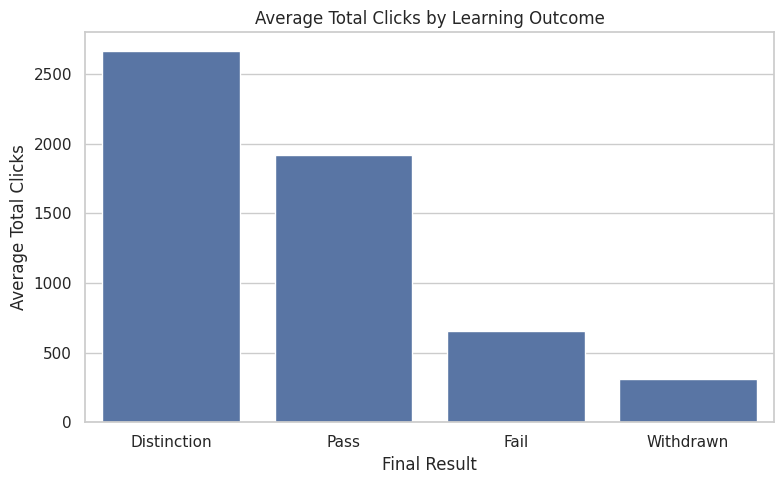

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=eda_data, x="final_result", y="total_clicks", order=result_order, errorbar=None)

plt.title("Average Total Clicks by Learning Outcome")
plt.xlabel("Final Result")
plt.ylabel("Average Total Clicks")

plt.tight_layout()

plt.savefig(images_path / "engagement_by_learning_outcome.png", dpi=300, bbox_inches="tight")

plt.show()

#### **Analisis Mahasiswa Tanpa Aktivitas VLE**

In [ ]:
no_activity = eda_data[eda_data["has_vle_activity"] == False]

print("Jumlah observasi tanpa aktivitas VLE:")
print(len(no_activity))

print("\nDistribusi final_result:")
print(no_activity["final_result"].value_counts())

print("\nPersentase:")
print(
    no_activity["final_result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Jumlah observasi tanpa aktivitas VLE:
3365

Distribusi final_result:
final_result
Withdrawn    2988
Fail          374
Pass            3
Name: count, dtype: int64

Persentase:
final_result
Withdrawn    88.80
Fail         11.11
Pass          0.09
Name: proportion, dtype: float64


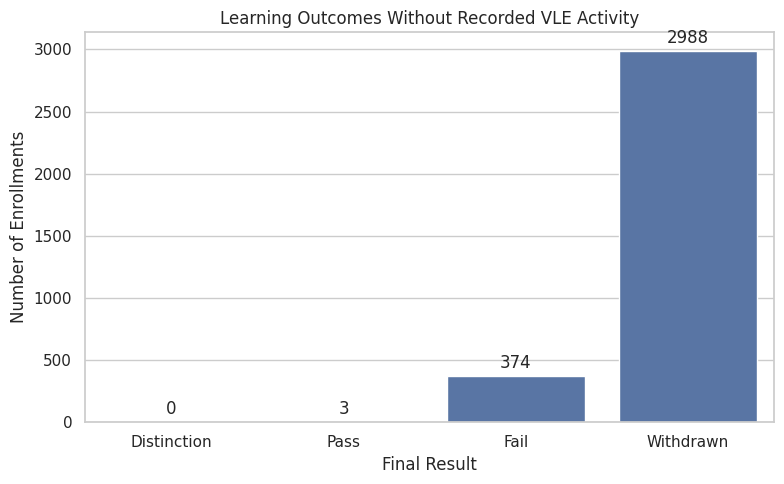

In [ ]:
# Visualisasi Tanpa Aktivitas VLE
no_activity_counts = (
    no_activity["final_result"]
    .value_counts()
    .reindex(result_order, fill_value=0)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(x=no_activity_counts.index, y=no_activity_counts.values)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Learning Outcomes Without Recorded VLE Activity")
plt.xlabel("Final Result")
plt.ylabel("Number of Enrollments")

plt.tight_layout()

plt.savefig(images_path / "no_vle_activity_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

#### **Menyimpan Dataset EDA**

In [ ]:
eda_data.to_csv(processed_path / "student_eda.csv", index=False)

print("EDA dataset berhasil disimpan.")

EDA dataset berhasil disimpan.


## **Dokumentasi & Temuan**

**1. Persiapan Data**

Dataset studentInfo digabungkan dengan student_engagement menggunakan LEFT JOIN berdasarkan kombinasi code_module, code_presentation, dan id_student.

Penggabungan menghasilkan 32.593 observasi mahasiswa-modul-periode, dengan rincian:

- 29.228 observasi (89,68%) memiliki aktivitas VLE tercatat.
- 3.365 observasi (10,32%) tidak memiliki aktivitas VLE tercatat.

Observasi tanpa aktivitas VLE diberi nilai 0 pada metrik engagement untuk kebutuhan analisis deskriptif. Kolom has_vle_activity tetap dipertahankan untuk membedakan observasi dengan dan tanpa catatan aktivitas.

**2. Distribusi Hasil Pembelajaran**

Distribusi hasil akhir pembelajaran menunjukkan:

| Final Result | Count | Percentage |
|---|---:|---:|
| Pass | 12.361 | 37,93% |
| Withdrawn | 10.156 | 31,16% |
| Fail | 7.052 | 21,64% |
| Distinction | 3.024 | 9,28% |

Kategori Pass memiliki jumlah observasi terbanyak, sedangkan Distinction memiliki jumlah paling sedikit.

Sebanyak 31,16% observasi berstatus Withdrawn, sehingga pengunduran diri menjadi salah satu aspek penting dalam analisis pembelajaran.

**3. Distribusi Keterlibatan mahasiswa**

Histogram total klik menunjukkan distribusi yang miring ke kanan (*right-skewed*).

Sebagian besar observasi memiliki jumlah klik relatif rendah, sedangkan sebagian kecil memiliki aktivitas jauh lebih tinggi.

Hal ini menunjukkan adanya variasi tingkat aktivitas pembelajaran yang cukup besar antarobservasi.

Transformasi logaritmik menggunakan log1p() diterapkan untuk membantu memperjelas distribusi aktivitas tanpa menghapus nilai ekstrem.

**4. Analisis Keterlibatan Berdasarkan Hasil Pembelajaran**

Hasil analisis rata-rata engagement berdasarkan hasil akhir pembelajaran adalah sebagai berikut:

| Final Result | Avg. Total Clicks | Avg. Active Days | Avg. Unique Resources |
|---|---:|---:|---:|
| Distinction | 2.666,76 | 110,04 | 102,45 |
| Pass | 1.921,81 | 87,04 | 89,06 |
| Fail | 651,85 | 33,18 | 43,08 |
| Withdrawn | 313,95 | 16,29 | 24,23 |

Observasi berstatus Distinction memiliki rata-rata engagement tertinggi pada ketiga metrik, sedangkan observasi berstatus Withdrawn memiliki rata-rata terendah.

Hasil ini menunjukkan adanya asosiasi positif secara deskriptif antara tingkat aktivitas pembelajaran dan hasil akhir yang lebih baik.

**5. Analisis mahasiswa Tanpa Aktivitas VLE**

Pemeriksaan terhadap 3.365 observasi tanpa aktivitas VLE tercatat menunjukkan:

| Final Result | Count | Percentage |
|---|---:|---:|
| Withdrawn | 2.988 | 88,80% |
| Fail | 374 | 11,11% |
| Pass | 3 | 0,09% |
| Distinction | 0 | 0,00% |

Sebanyak 88,80% observasi tanpa aktivitas VLE berstatus Withdrawn.

Selain itu, 2.988 dari 10.156 observasi berstatus Withdrawn (29,42%) tidak memiliki aktivitas VLE tercatat.

Temuan ini menunjukkan adanya hubungan deskriptif antara ketiadaan aktivitas VLE dan status pengunduran diri.

**6. Temuan Utama**

1. Sebanyak 10,32% observasi tidak memiliki aktivitas VLE tercatat.
2. Distribusi total klik bersifat *right-skewed*, menunjukkan adanya perbedaan tingkat aktivitas yang cukup besar antarobservasi.
3. Observasi dengan hasil pembelajaran lebih baik cenderung memiliki rata-rata engagement lebih tinggi.
4. Sebanyak 88,80% observasi tanpa aktivitas VLE berstatus Withdrawn.
5. Sekitar 29,42% dari seluruh observasi Withdrawn tidak memiliki aktivitas VLE tercatat.

**7. Wawasan Bisnis:**

Aktivitas pembelajaran berpotensi digunakan sebagai salah satu indikator untuk membantu institusi pendidikan memantau keterlibatan mahasiswa.

Observasi tanpa aktivitas VLE tercatat dan observasi dengan tingkat engagement rendah dapat menjadi kelompok yang relevan untuk ditinjau lebih lanjut dalam pengembangan strategi dukungan pembelajaran.

Namun, diperlukan analisis tambahan mengenai waktu aktivitas dan pengunduran diri sebelum indikator tersebut digunakan untuk mengidentifikasi risiko secara individual.

**8. Keterbatasan Analisis**

- Tidak adanya catatan aktivitas VLE tidak selalu berarti mahasiswa tidak melakukan aktivitas pembelajaran di luar platform.
- Total klik tidak secara langsung mengukur pemahaman atau kualitas pembelajaran.
- Durasi partisipasi dapat memengaruhi total aktivitas, terutama pada mahasiswa yang mengundurkan diri.
- Catatan aktivitas berulang pada studentVle dipertahankan sesuai keputusan data cleaning Day 2.
- Analisis bersifat deskriptif sehingga tidak dapat membuktikan hubungan sebab-akibat.
- Unit analisis adalah observasi mahasiswa-modul-periode, bukan jumlah mahasiswa unik.